In [1]:
import kagglehub
path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")

Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.


In [2]:
import pandas as pd
import os

# The correct filename for this dataset is typically 'WA_Fn-UseC_-HR-Employee-Attrition.csv'
dataset_file_path = os.path.join(path, 'WA_Fn-UseC_-HR-Employee-Attrition.csv')

df = pd.read_csv(dataset_file_path)

# Display the first 5 rows of the DataFrame
display(df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [4]:
# Duplicate records
df.duplicated().sum()

np.int64(0)

In [5]:
# Check unique values
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")

Age: 43
Attrition: 2
BusinessTravel: 3
DailyRate: 886
Department: 3
DistanceFromHome: 29
Education: 5
EducationField: 6
EmployeeCount: 1
EmployeeNumber: 1470
EnvironmentSatisfaction: 4
Gender: 2
HourlyRate: 71
JobInvolvement: 4
JobLevel: 5
JobRole: 9
JobSatisfaction: 4
MaritalStatus: 3
MonthlyIncome: 1349
MonthlyRate: 1427
NumCompaniesWorked: 10
Over18: 1
OverTime: 2
PercentSalaryHike: 15
PerformanceRating: 2
RelationshipSatisfaction: 4
StandardHours: 1
StockOptionLevel: 4
TotalWorkingYears: 40
TrainingTimesLastYear: 7
WorkLifeBalance: 4
YearsAtCompany: 37
YearsInCurrentRole: 19
YearsSinceLastPromotion: 16
YearsWithCurrManager: 18


In [6]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [7]:
# Summary for categorical columns
df.describe(include='object').T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [8]:
df_clean = df.copy()

In [9]:
duplicates = df_clean.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

Duplicate rows: 0


In [10]:
df_clean.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [11]:
missing = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Percentage": (df_clean.isnull().sum()/len(df_clean)*100)
})

missing

,Missing Values,Percentage
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


In [12]:
for col in df_clean.columns:
    if df_clean[col].nunique() == 1:
        print(col)

EmployeeCount
Over18
StandardHours


In [13]:
df_clean.drop(
    columns=[
        "EmployeeCount",
        "Over18",
        "StandardHours",
        "EmployeeNumber"
    ],
    inplace=True
)

In [14]:
df_clean.shape

(1470, 31)

In [15]:
df_clean.dtypes

,0
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EnvironmentSatisfaction,int64
Gender,object


In [16]:
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df_clean[col].value_counts())


Attrition
Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Department
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

EducationField
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Gender
Gender
Male      882
Female    588
Name: count, dtype: int64

JobRole
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     673


In [17]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.00,4.0
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.00,19999.0


In [18]:
df_clean.to_csv(
    "clean_hr_data.csv",
    index=False
)

In [19]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[18,30,40,50,60],
    labels=["18-30","31-40","41-50","51-60"]
)

In [20]:
df_clean["IncomeGroup"] = pd.qcut(
    df_clean["MonthlyIncome"],
    q=4,
    labels=["Low","Medium","High","Very High"]
)

In [21]:
df_clean["ExperienceLevel"] = pd.cut(
    df_clean["TotalWorkingYears"],
    bins=[0,5,10,20,40],
    labels=["Junior","Mid","Senior","Expert"]
)

In [22]:
print(f"Total Employees: {len(df_clean)}")

print(f"Departments: {df_clean['Department'].nunique()}")

print(f"Job Roles: {df_clean['JobRole'].nunique()}")

print(f"Average Age: {df_clean['Age'].mean():.1f}")

print(f"Average Monthly Income: ${df_clean['MonthlyIncome'].mean():,.0f}")

Total Employees: 1470
Departments: 3
Job Roles: 9
Average Age: 36.9
Average Monthly Income: $6,503


In [23]:
# Basic Workforce KPIs

total_employees = len(df_clean)
total_departments = df_clean['Department'].nunique()
total_job_roles = df_clean['JobRole'].nunique()

average_age = df_clean['Age'].mean()
average_income = df_clean['MonthlyIncome'].mean()
average_tenure = df_clean['YearsAtCompany'].mean()

print(f"Total Employees      : {total_employees}")
print(f"Departments          : {total_departments}")
print(f"Job Roles            : {total_job_roles}")
print(f"Average Age          : {average_age:.2f}")
print(f"Average Income       : ${average_income:,.2f}")
print(f"Average Tenure       : {average_tenure:.2f} years")

Total Employees      : 1470
Departments          : 3
Job Roles            : 9
Average Age          : 36.92
Average Income       : $6,502.93
Average Tenure       : 7.01 years


In [24]:
department_counts = df_clean['Department'].value_counts()

department_counts

,count
Department,
Research & Development,961
Sales,446
Human Resources,63


In [25]:
department_percentage = (
    df_clean['Department']
    .value_counts(normalize=True) * 100
).round(2)

department_percentage

,proportion
Department,
Research & Development,65.37
Sales,30.34
Human Resources,4.29


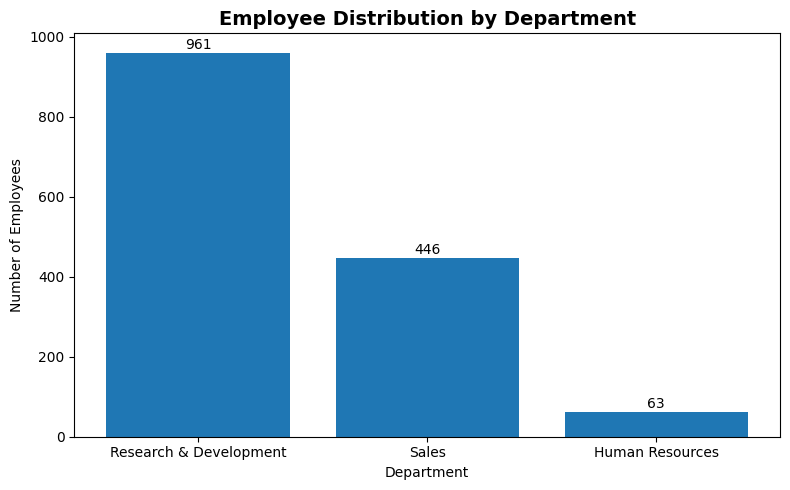

In [26]:
import matplotlib.pyplot as plt

department_counts = df_clean['Department'].value_counts()

plt.figure(figsize=(8,5))

bars = plt.bar(
    department_counts.index,
    department_counts.values
)

plt.title("Employee Distribution by Department", fontsize=14, weight='bold')
plt.xlabel("Department")
plt.ylabel("Number of Employees")

# Add value labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 10,
        int(bar.get_height()),
        ha='center',
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [27]:
gender_counts = df_clean['Gender'].value_counts()

print(gender_counts)

Gender
Male      882
Female    588
Name: count, dtype: int64


In [28]:
gender_percentage = (
    df_clean['Gender']
    .value_counts(normalize=True) * 100
).round(2)

print(gender_percentage)

Gender
Male      60.0
Female    40.0
Name: proportion, dtype: float64


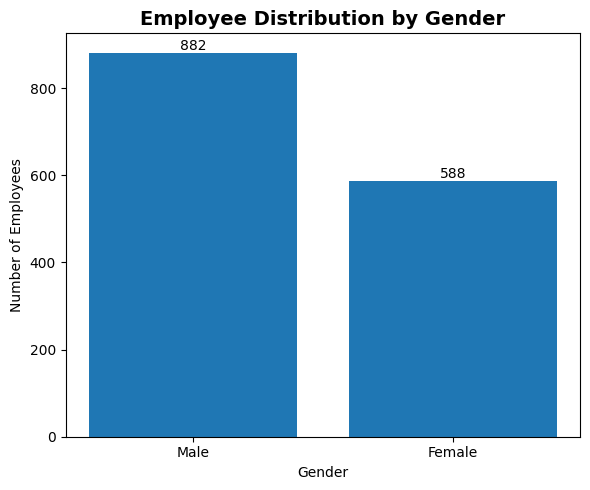

In [29]:
import matplotlib.pyplot as plt

gender_counts = df_clean['Gender'].value_counts()

plt.figure(figsize=(6,5))

bars = plt.bar(
    gender_counts.index,
    gender_counts.values
)

plt.title("Employee Distribution by Gender", fontsize=14, weight='bold')
plt.xlabel("Gender")
plt.ylabel("Number of Employees")

# Add value labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        int(bar.get_height()),
        ha='center'
    )

plt.tight_layout()
plt.show()

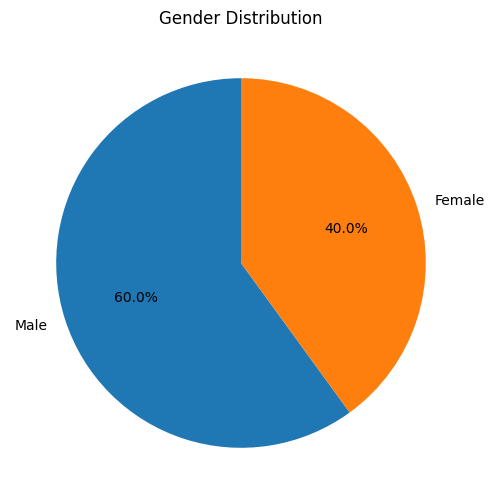

In [30]:
plt.figure(figsize=(6,6))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Gender Distribution")

plt.show()

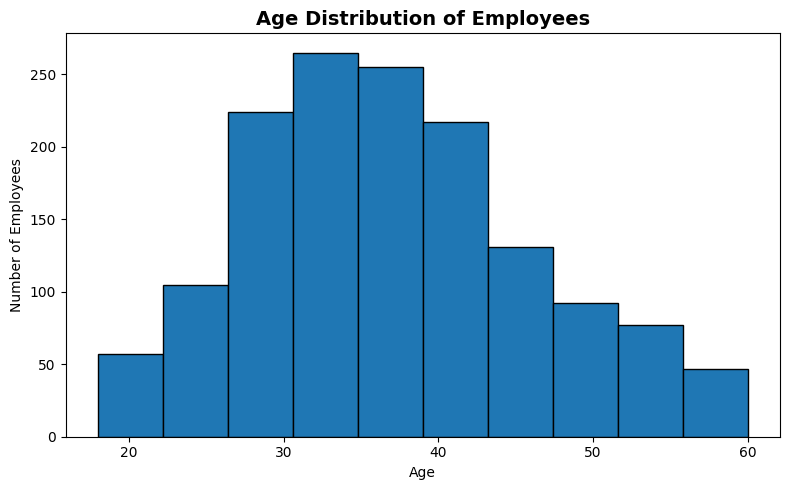

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    df_clean['Age'],
    bins=10,
    edgecolor='black'
)

plt.title("Age Distribution of Employees", fontsize=14, weight='bold')
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

In [32]:
df_clean['Age'].describe()

,Age
count,1470.000000
mean,36.923810
std,9.135373
min,18.000000
25%,30.000000
50%,36.000000
75%,43.000000
max,60.000000


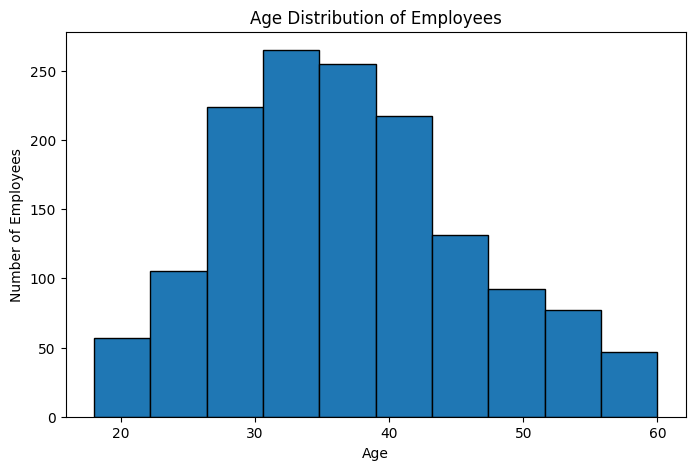

In [33]:
plt.figure(figsize=(8,5))

plt.hist(df_clean['Age'], bins=10, edgecolor='black')

plt.title("Age Distribution of Employees")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

In [34]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[18, 25, 35, 45, 60],
    labels=["18-25", "26-35", "36-45", "46-60"],
    include_lowest=True
)

In [35]:
age_group_counts = df_clean["AgeGroup"].value_counts().sort_index()
print(age_group_counts)

AgeGroup
18-25    123
26-35    606
36-45    468
46-60    273
Name: count, dtype: int64


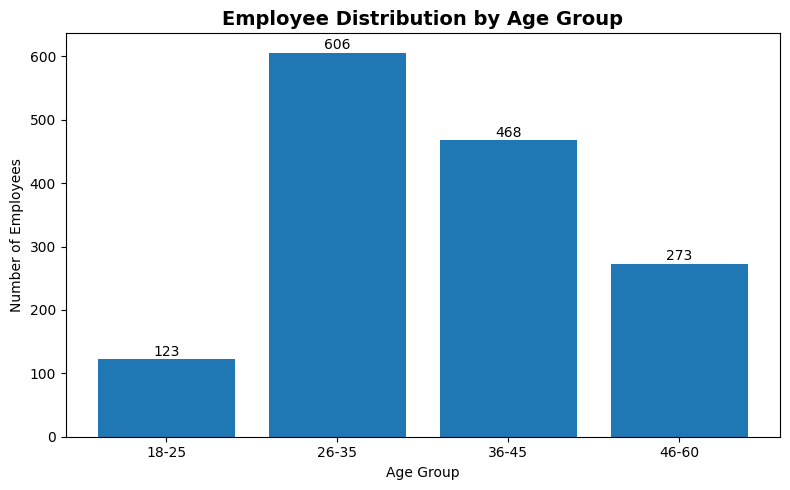

In [36]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    age_group_counts.index.astype(str),
    age_group_counts.values
)

plt.title("Employee Distribution by Age Group", fontsize=14, weight='bold')
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        int(bar.get_height()),
        ha='center'
    )

plt.tight_layout()
plt.show()

In [37]:
df_clean["Education"].unique()


array([2, 1, 4, 3, 5])

In [38]:
education_map = {
    1: "Below College",
    2: "College",
    3: "Bachelor",
    4: "Master",
    5: "Doctor"
}

df_clean["EducationLevel"] = df_clean["Education"].map(education_map)

In [39]:
education_counts = (
    df_clean["EducationLevel"]
    .value_counts()
)

print(education_counts)

EducationLevel
Bachelor         572
Master           398
College          282
Below College    170
Doctor            48
Name: count, dtype: int64


In [40]:
education_percentage = (
    df_clean["EducationLevel"]
    .value_counts(normalize=True) * 100
).round(2)

print(education_percentage)

EducationLevel
Bachelor         38.91
Master           27.07
College          19.18
Below College    11.56
Doctor            3.27
Name: proportion, dtype: float64


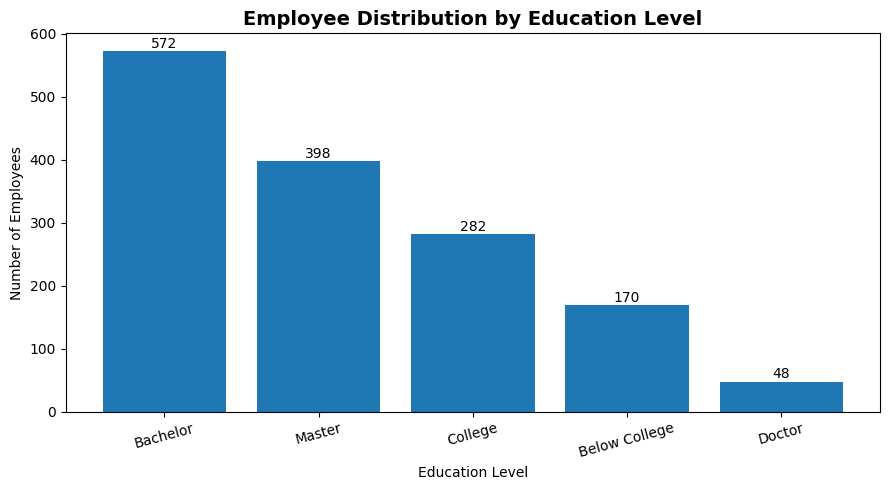

In [41]:
import matplotlib.pyplot as plt

education_counts = (
    df_clean["EducationLevel"]
    .value_counts()
)

plt.figure(figsize=(9,5))

bars = plt.bar(
    education_counts.index,
    education_counts.values
)

plt.title(
    "Employee Distribution by Education Level",
    fontsize=14,
    weight="bold"
)

plt.xlabel("Education Level")
plt.ylabel("Number of Employees")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+5,
        int(bar.get_height()),
        ha='center'
    )

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [42]:
df_clean["JobRole"].unique()

array(['Sales Executive', 'Research Scientist', 'Laboratory Technician',
       'Manufacturing Director', 'Healthcare Representative', 'Manager',
       'Sales Representative', 'Research Director', 'Human Resources'],
      dtype=object)

In [43]:
jobrole_counts = df_clean["JobRole"].value_counts()

print(jobrole_counts)

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64


In [44]:
jobrole_percentage = (
    df_clean["JobRole"]
    .value_counts(normalize=True) * 100
).round(2)

print(jobrole_percentage)

JobRole
Sales Executive              22.18
Research Scientist           19.86
Laboratory Technician        17.62
Manufacturing Director        9.86
Healthcare Representative     8.91
Manager                       6.94
Sales Representative          5.65
Research Director             5.44
Human Resources               3.54
Name: proportion, dtype: float64


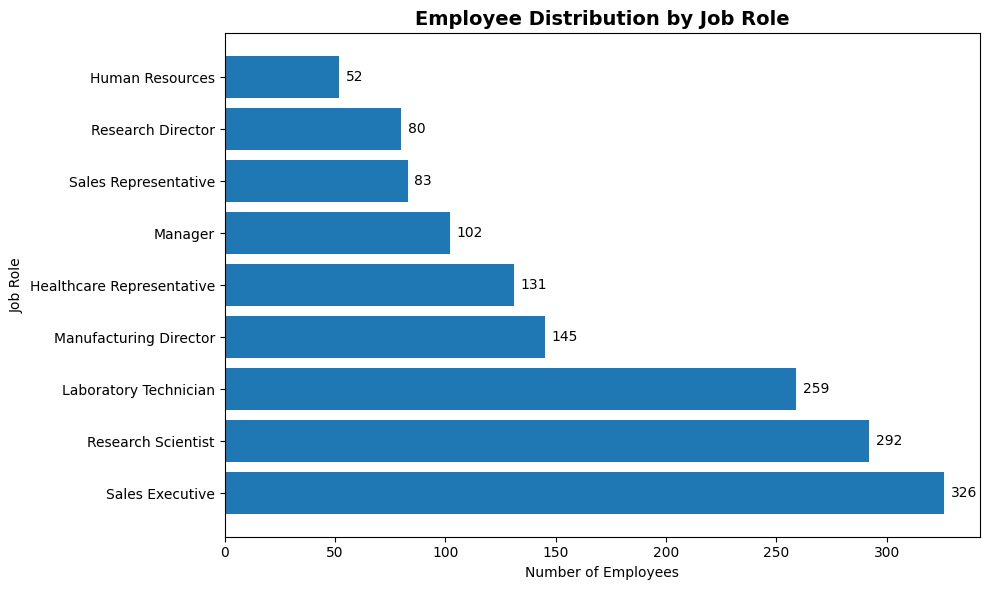

In [45]:
import matplotlib.pyplot as plt

jobrole_counts = df_clean["JobRole"].value_counts()

plt.figure(figsize=(10,6))

bars = plt.barh(
    jobrole_counts.index,
    jobrole_counts.values
)

plt.title(
    "Employee Distribution by Job Role",
    fontsize=14,
    weight="bold"
)

plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

# Add value labels
for bar in bars:
    plt.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height()/2,
        int(bar.get_width()),
        va="center"
    )

plt.tight_layout()
plt.show()

In [46]:
df_clean["Attrition"].unique()

array(['Yes', 'No'], dtype=object)

In [47]:
attrition_counts = df_clean["Attrition"].value_counts()

print(attrition_counts)

Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [48]:
employees_left = attrition_counts["Yes"]
total_employees = len(df_clean)

attrition_rate = (employees_left / total_employees) * 100

print(f"Attrition Rate: {attrition_rate:.2f}%")

Attrition Rate: 16.12%


In [49]:
employees_stayed = attrition_counts["No"]

print(f"Employees Stayed : {employees_stayed}")
print(f"Employees Left   : {employees_left}")

Employees Stayed : 1233
Employees Left   : 237


In [50]:
print("="*35)
print("HR ATTRITION KPI")
print("="*35)

print(f"Total Employees : {total_employees}")
print(f"Employees Stayed: {employees_stayed}")
print(f"Employees Left  : {employees_left}")
print(f"Attrition Rate  : {attrition_rate:.2f}%")

HR ATTRITION KPI
Total Employees : 1470
Employees Stayed: 1233
Employees Left  : 237
Attrition Rate  : 16.12%


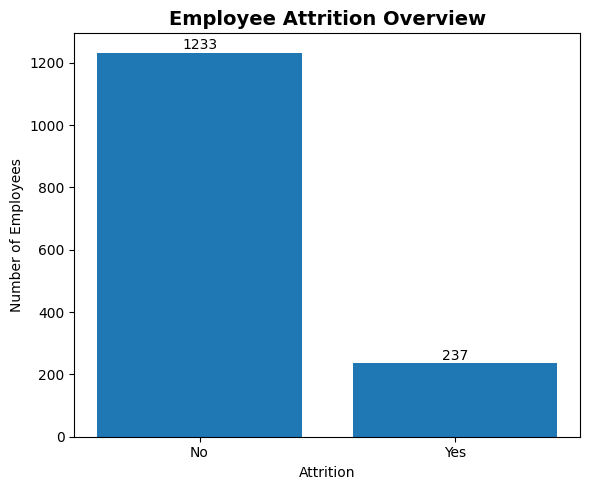

In [51]:
import matplotlib.pyplot as plt

attrition_counts = df_clean["Attrition"].value_counts()

plt.figure(figsize=(6,5))

bars = plt.bar(
    attrition_counts.index,
    attrition_counts.values
)

plt.title(
    "Employee Attrition Overview",
    fontsize=14,
    weight='bold'
)

plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+10,
        int(bar.get_height()),
        ha='center'
    )

plt.tight_layout()
plt.show()

In [52]:
department_total = df_clean["Department"].value_counts()

department_total

,count
Department,
Research & Development,961
Sales,446
Human Resources,63


In [53]:
department_left = (
    df_clean[df_clean["Attrition"]=="Yes"]
    ["Department"]
    .value_counts()
)

department_left

,count
Department,
Research & Development,133
Sales,92
Human Resources,12


In [54]:
department_summary = pd.DataFrame({
    "Total Employees": department_total,
    "Employees Left": department_left
})

department_summary

,Total Employees,Employees Left
Department,,
Research & Development,961,133
Sales,446,92
Human Resources,63,12


In [55]:
department_summary["Attrition Rate (%)"] = (
    department_summary["Employees Left"] /
    department_summary["Total Employees"]
) * 100

department_summary

,Total Employees,Employees Left,Attrition Rate (%)
Department,,,
Research & Development,961,133,13.839750
Sales,446,92,20.627803
Human Resources,63,12,19.047619


In [56]:
department_summary["Attrition Rate (%)"] = (
    department_summary["Attrition Rate (%)"]
    .round(2)
)

department_summary

,Total Employees,Employees Left,Attrition Rate (%)
Department,,,
Research & Development,961,133,13.84
Sales,446,92,20.63
Human Resources,63,12,19.05


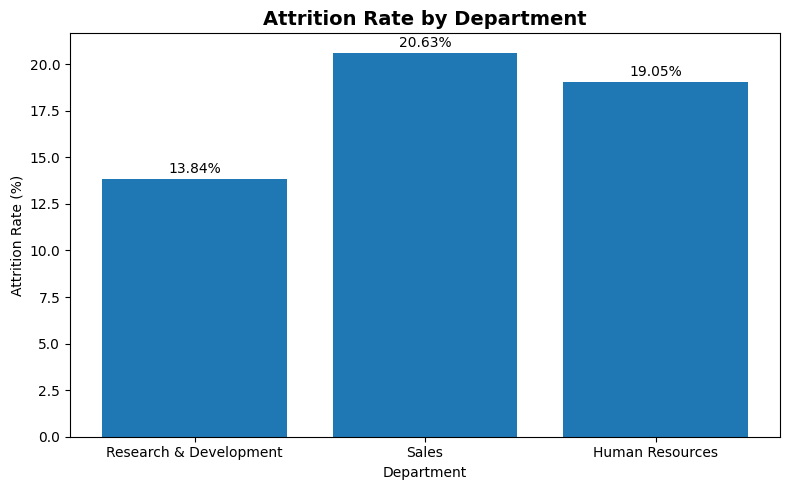

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

bars = plt.bar(
    department_summary.index,
    department_summary["Attrition Rate (%)"]
)

plt.title(
    "Attrition Rate by Department",
    fontsize=14,
    weight="bold"
)

plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.3,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [58]:
jobrole_total = df_clean["JobRole"].value_counts()

jobrole_total

,count
JobRole,
Sales Executive,326
Research Scientist,292
Laboratory Technician,259
Manufacturing Director,145
Healthcare Representative,131
Manager,102
Sales Representative,83
Research Director,80
Human Resources,52


In [59]:
jobrole_left = (
    df_clean[df_clean["Attrition"] == "Yes"]
    ["JobRole"]
    .value_counts()
)

jobrole_left

,count
JobRole,
Laboratory Technician,62
Sales Executive,57
Research Scientist,47
Sales Representative,33
Human Resources,12
Manufacturing Director,10
Healthcare Representative,9
Manager,5
Research Director,2


In [60]:
jobrole_summary = pd.DataFrame({
    "Total Employees": jobrole_total,
    "Employees Left": jobrole_left
})

jobrole_summary = jobrole_summary.fillna(0)
jobrole_summary["Employees Left"] = jobrole_summary["Employees Left"].astype(int)

jobrole_summary

,Total Employees,Employees Left
JobRole,,
Healthcare Representative,131,9
Human Resources,52,12
Laboratory Technician,259,62
Manager,102,5
Manufacturing Director,145,10
Research Director,80,2
Research Scientist,292,47
Sales Executive,326,57
Sales Representative,83,33


In [61]:
jobrole_summary["Attrition Rate (%)"] = (
    jobrole_summary["Employees Left"]
    / jobrole_summary["Total Employees"]
) * 100

jobrole_summary["Attrition Rate (%)"] = (
    jobrole_summary["Attrition Rate (%)"]
    .round(2)
)

In [62]:
jobrole_summary = jobrole_summary.sort_values(
    by="Attrition Rate (%)",
    ascending=False
)

jobrole_summary

,Total Employees,Employees Left,Attrition Rate (%)
JobRole,,,
Sales Representative,83,33,39.76
Laboratory Technician,259,62,23.94
Human Resources,52,12,23.08
Sales Executive,326,57,17.48
Research Scientist,292,47,16.10
Manufacturing Director,145,10,6.90
Healthcare Representative,131,9,6.87
Manager,102,5,4.90
Research Director,80,2,2.50


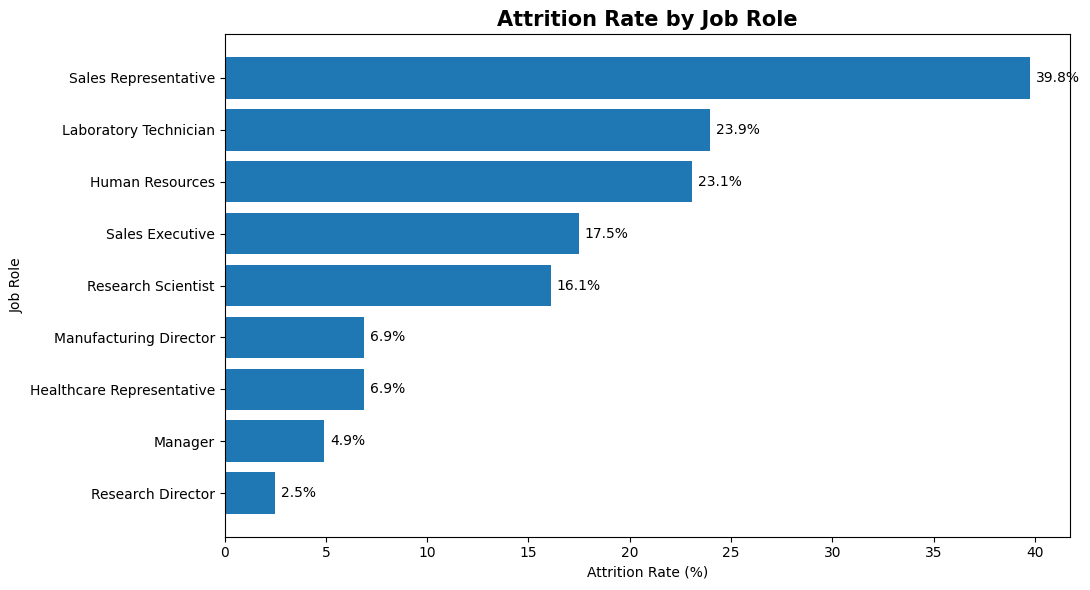

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11,6))

bars = plt.barh(
    jobrole_summary.index,
    jobrole_summary["Attrition Rate (%)"]
)

plt.title(
    "Attrition Rate by Job Role",
    fontsize=15,
    weight="bold"
)

plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

for bar in bars:
    plt.text(
        bar.get_width()+0.3,
        bar.get_y()+bar.get_height()/2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

plt.gca().invert_yaxis()   # Highest attrition at the top

plt.tight_layout()

plt.show()

In [64]:
df_clean["OverTime"].value_counts()

,count
OverTime,
No,1054
Yes,416


In [65]:
overtime_table = pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"]
)

overtime_table

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [66]:
overtime_summary = overtime_table.copy()

overtime_summary["Total Employees"] = overtime_summary.sum(axis=1)

overtime_summary["Attrition Rate (%)"] = (
    overtime_summary["Yes"] /
    overtime_summary["Total Employees"]
) * 100

overtime_summary["Attrition Rate (%)"] = overtime_summary["Attrition Rate (%)"].round(2)

overtime_summary

Attrition,No,Yes,Total Employees,Attrition Rate (%)
OverTime,,,,
No,944,110,1054,10.44
Yes,289,127,416,30.53


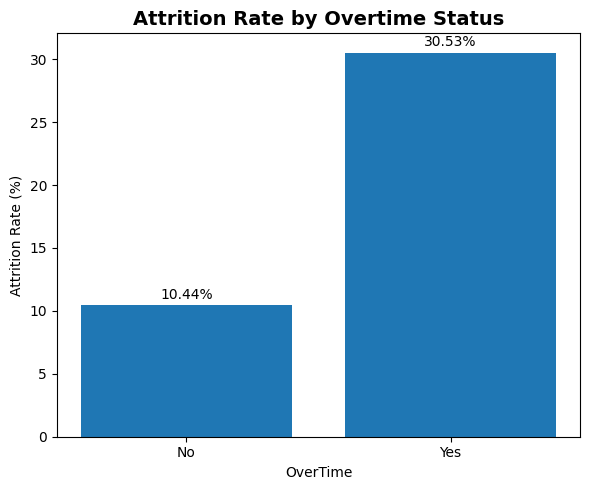

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

bars = plt.bar(
    overtime_summary.index,
    overtime_summary["Attrition Rate (%)"]
)

plt.title(
    "Attrition Rate by Overtime Status",
    fontsize=14,
    weight="bold"
)

plt.xlabel("OverTime")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.5,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.show()

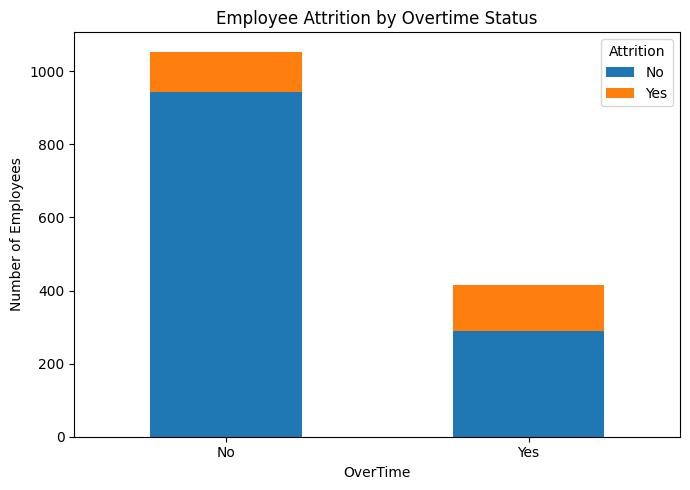

In [68]:
overtime_table.plot(
    kind="bar",
    stacked=True,
    figsize=(7,5)
)

plt.title("Employee Attrition by Overtime Status")
plt.xlabel("OverTime")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

In [69]:
df_clean["MonthlyIncome"].describe()

,MonthlyIncome
count,1470.000000
mean,6502.931293
std,4707.956783
min,1009.000000
25%,2911.000000
50%,4919.000000
75%,8379.000000
max,19999.000000


In [70]:
df_clean.groupby("Attrition")["MonthlyIncome"].describe()

,count,mean,std,min,25%,50%,75%,max
Attrition,,,,,,,,
No,1233.0,6832.739659,4818.208001,1051.0,3211.0,5204.0,8834.0,19999.0
Yes,237.0,4787.092827,3640.210367,1009.0,2373.0,3202.0,5916.0,19859.0


In [71]:
income_summary = (
    df_clean
    .groupby("Attrition")["MonthlyIncome"]
    .mean()
    .round(2)
)

print(income_summary)

Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64


<Figure size 800x600 with 0 Axes>

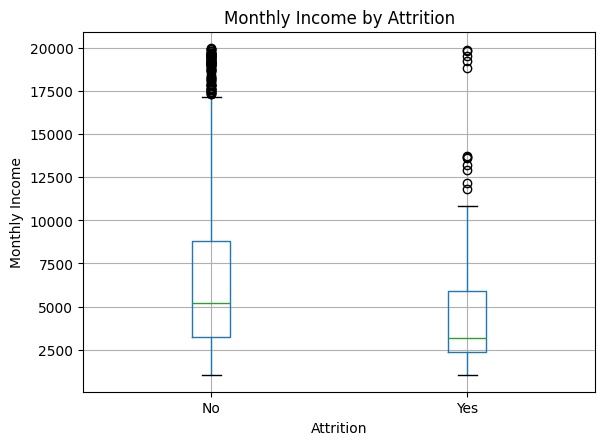

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

df_clean.boxplot(
    column="MonthlyIncome",
    by="Attrition"
)

plt.title("Monthly Income by Attrition")
plt.suptitle("")   # Removes automatic pandas title
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

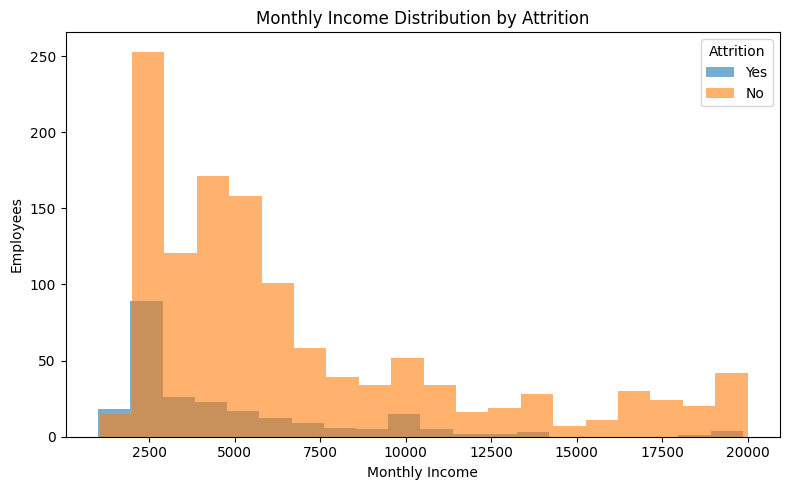

In [73]:
plt.figure(figsize=(8,5))

for status in ["Yes", "No"]:
    plt.hist(
        df_clean[df_clean["Attrition"] == status]["MonthlyIncome"],
        bins=20,
        alpha=0.6,
        label=status
    )

plt.title("Monthly Income Distribution by Attrition")
plt.xlabel("Monthly Income")
plt.ylabel("Employees")
plt.legend(title="Attrition")

plt.tight_layout()
plt.show()

In [74]:
df_clean["IncomeGroup"] = pd.qcut(
    df_clean["MonthlyIncome"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

In [75]:
income_attrition = pd.crosstab(
    df_clean["IncomeGroup"],
    df_clean["Attrition"]
)

income_attrition

Attrition,No,Yes
IncomeGroup,,
Low,261,108
Medium,314,52
High,328,39
Very High,330,38


In [76]:
income_attrition["Total"] = income_attrition.sum(axis=1)

income_attrition["Attrition Rate (%)"] = (
    income_attrition["Yes"]
    / income_attrition["Total"]
) * 100

income_attrition = income_attrition.round(2)

income_attrition

Attrition,No,Yes,Total,Attrition Rate (%)
IncomeGroup,,,,
Low,261,108,369,29.27
Medium,314,52,366,14.21
High,328,39,367,10.63
Very High,330,38,368,10.33


Attrition,No,Yes,Total Employees,Attrition Rate (%)
EnvironmentLevel,,,,
High,391,62,453,13.69
Low,212,72,284,25.35
Medium,244,43,287,14.98
Very High,386,60,446,13.45


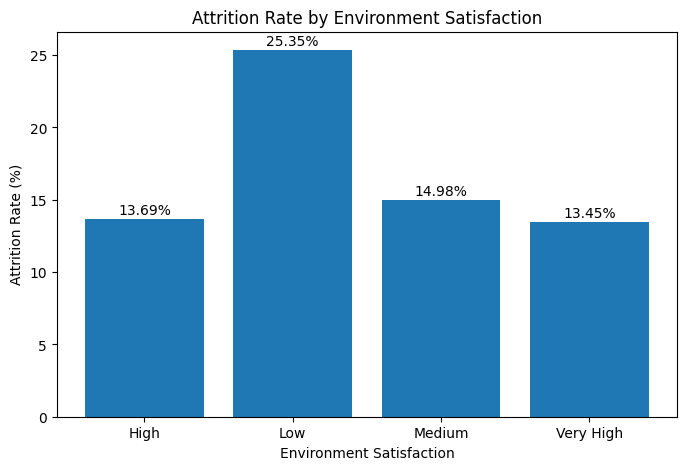

In [77]:
# Environment Satisfaction vs Attrition

env_map = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

df_clean["EnvironmentLevel"] = df_clean["EnvironmentSatisfaction"].map(env_map)

env_summary = pd.crosstab(
    df_clean["EnvironmentLevel"],
    df_clean["Attrition"]
)

env_summary["Total Employees"] = env_summary.sum(axis=1)

env_summary["Attrition Rate (%)"] = (
    env_summary["Yes"] /
    env_summary["Total Employees"] * 100
).round(2)

display(env_summary)

plt.figure(figsize=(8,5))

bars = plt.bar(
    env_summary.index,
    env_summary["Attrition Rate (%)"]
)

plt.title("Attrition Rate by Environment Satisfaction")
plt.xlabel("Environment Satisfaction")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.3,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.show()

Attrition,No,Yes,Total Employees,Attrition Rate (%)
WorkLifeLevel,,,,
Bad,55,25,80,31.25
Best,126,27,153,17.65
Better,766,127,893,14.22
Good,286,58,344,16.86


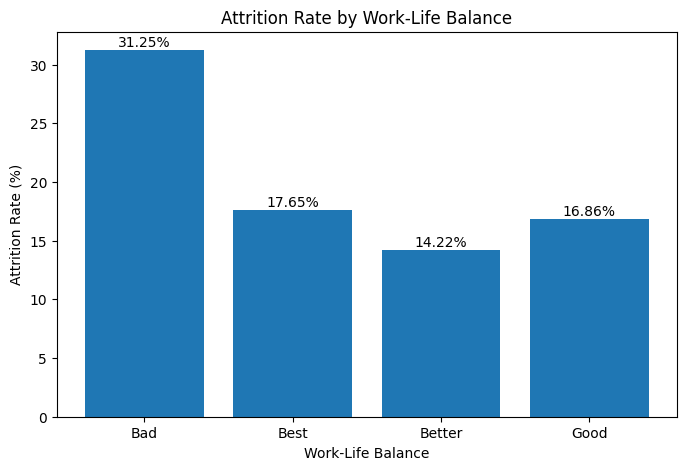

In [78]:
# Work-Life Balance vs Attrition

wlb_map = {
    1:"Bad",
    2:"Good",
    3:"Better",
    4:"Best"
}

df_clean["WorkLifeLevel"] = df_clean["WorkLifeBalance"].map(wlb_map)

wlb_summary = pd.crosstab(
    df_clean["WorkLifeLevel"],
    df_clean["Attrition"]
)

wlb_summary["Total Employees"] = wlb_summary.sum(axis=1)

wlb_summary["Attrition Rate (%)"] = (
    wlb_summary["Yes"] /
    wlb_summary["Total Employees"] *100
).round(2)

display(wlb_summary)

plt.figure(figsize=(8,5))

bars = plt.bar(
    wlb_summary.index,
    wlb_summary["Attrition Rate (%)"]
)

plt.title("Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.3,
             f"{bar.get_height():.2f}%",
             ha="center")

plt.show()

Attrition,No,Yes,Total Employees,Attrition Rate (%)
RelationshipLevel,,,,
High,388,71,459,15.47
Low,219,57,276,20.65
Medium,258,45,303,14.85
Very High,368,64,432,14.81


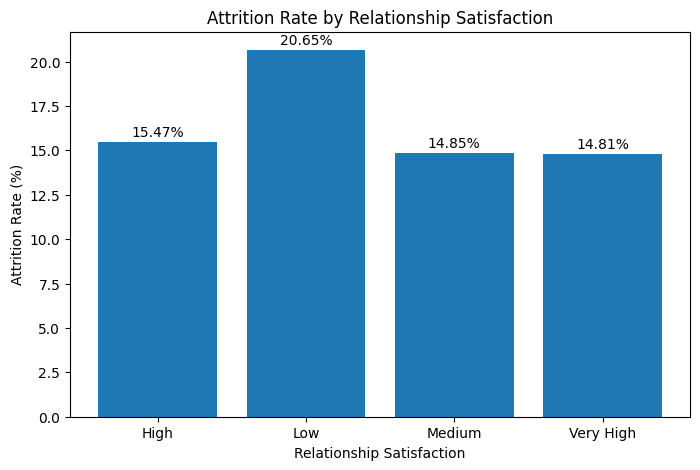

In [79]:
# Relationship Satisfaction vs Attrition

relation_map = {
    1:"Low",
    2:"Medium",
    3:"High",
    4:"Very High"
}

df_clean["RelationshipLevel"] = df_clean["RelationshipSatisfaction"].map(relation_map)

relation_summary = pd.crosstab(
    df_clean["RelationshipLevel"],
    df_clean["Attrition"]
)

relation_summary["Total Employees"] = relation_summary.sum(axis=1)

relation_summary["Attrition Rate (%)"] = (
    relation_summary["Yes"] /
    relation_summary["Total Employees"]*100
).round(2)

display(relation_summary)

plt.figure(figsize=(8,5))

bars = plt.bar(
    relation_summary.index,
    relation_summary["Attrition Rate (%)"]
)

plt.title("Attrition Rate by Relationship Satisfaction")
plt.xlabel("Relationship Satisfaction")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.3,
             f"{bar.get_height():.2f}%",
             ha="center")

plt.show()

<Figure size 900x500 with 0 Axes>

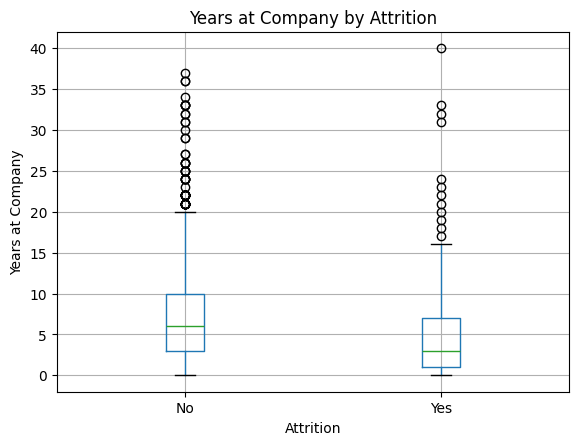

In [80]:
# Years at Company vs Attrition

plt.figure(figsize=(9,5))

df_clean.boxplot(
    column="YearsAtCompany",
    by="Attrition"
)

plt.title("Years at Company by Attrition")
plt.suptitle("")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

<Figure size 900x500 with 0 Axes>

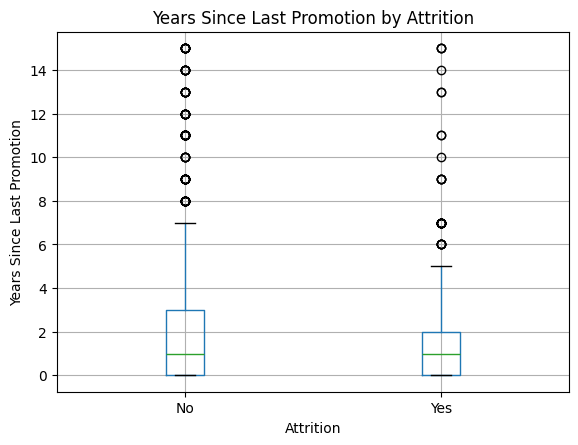

In [81]:
# Years Since Last Promotion vs Attrition

plt.figure(figsize=(9,5))

df_clean.boxplot(
    column="YearsSinceLastPromotion",
    by="Attrition"
)

plt.title("Years Since Last Promotion by Attrition")
plt.suptitle("")
plt.xlabel("Attrition")
plt.ylabel("Years Since Last Promotion")

plt.show()

Attrition,No,Yes,Total Employees,Attrition Rate (%)
BusinessTravel,,,,
Non-Travel,138,12,150,8.00
Travel_Frequently,208,69,277,24.91
Travel_Rarely,887,156,1043,14.96


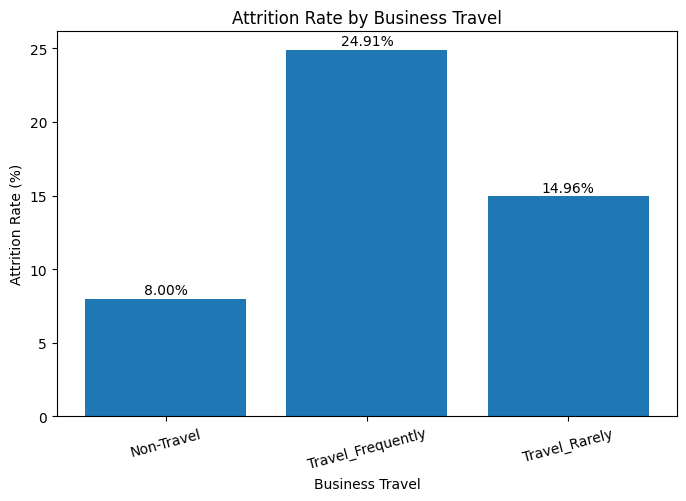

In [82]:
# Business Travel vs Attrition

travel_summary = pd.crosstab(
    df_clean["BusinessTravel"],
    df_clean["Attrition"]
)

travel_summary["Total Employees"] = travel_summary.sum(axis=1)

travel_summary["Attrition Rate (%)"] = (
    travel_summary["Yes"] /
    travel_summary["Total Employees"]*100
).round(2)

display(travel_summary)

plt.figure(figsize=(8,5))

bars = plt.bar(
    travel_summary.index,
    travel_summary["Attrition Rate (%)"]
)

plt.title("Attrition Rate by Business Travel")
plt.xlabel("Business Travel")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.3,
             f"{bar.get_height():.2f}%",
             ha="center")

plt.xticks(rotation=15)

plt.show()

Attrition,No,Yes,Total Employees,Attrition Rate (%)
MaritalStatus,,,,
Divorced,294,33,327,10.09
Married,589,84,673,12.48
Single,350,120,470,25.53


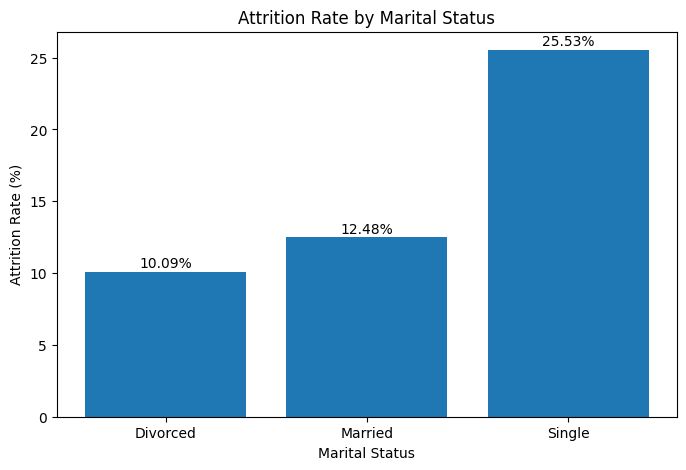

In [83]:
# Marital Status vs Attrition

marital_summary = pd.crosstab(
    df_clean["MaritalStatus"],
    df_clean["Attrition"]
)

marital_summary["Total Employees"] = marital_summary.sum(axis=1)

marital_summary["Attrition Rate (%)"] = (
    marital_summary["Yes"] /
    marital_summary["Total Employees"]*100
).round(2)

display(marital_summary)

plt.figure(figsize=(8,5))

bars = plt.bar(
    marital_summary.index,
    marital_summary["Attrition Rate (%)"]
)

plt.title("Attrition Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.3,
             f"{bar.get_height():.2f}%",
             ha="center")

plt.show()

Attrition,No,Yes,Total Employees,Attrition Rate (%)
JobLevel,,,,
1,400,143,543,26.34
2,482,52,534,9.74
3,186,32,218,14.68
4,101,5,106,4.72
5,64,5,69,7.25


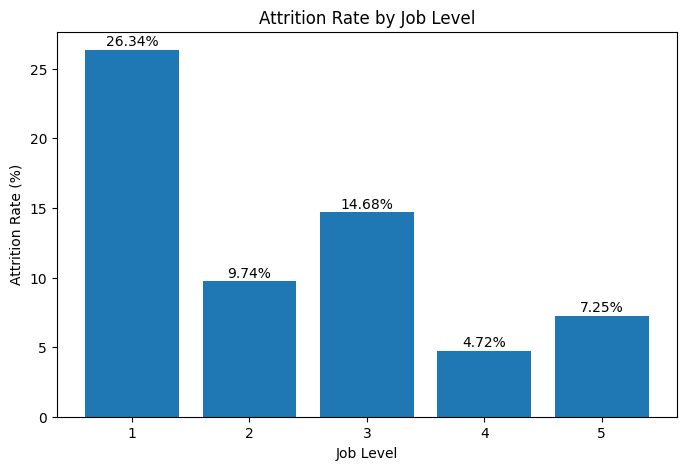

In [84]:
# Job Level vs Attrition

level_summary = pd.crosstab(
    df_clean["JobLevel"],
    df_clean["Attrition"]
)

level_summary["Total Employees"] = level_summary.sum(axis=1)

level_summary["Attrition Rate (%)"] = (
    level_summary["Yes"] /
    level_summary["Total Employees"]*100
).round(2)

display(level_summary)

plt.figure(figsize=(8,5))

bars = plt.bar(
    level_summary.index.astype(str),
    level_summary["Attrition Rate (%)"]
)

plt.title("Attrition Rate by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Attrition Rate (%)")

for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.3,
             f"{bar.get_height():.2f}%",
             ha="center")

plt.show()

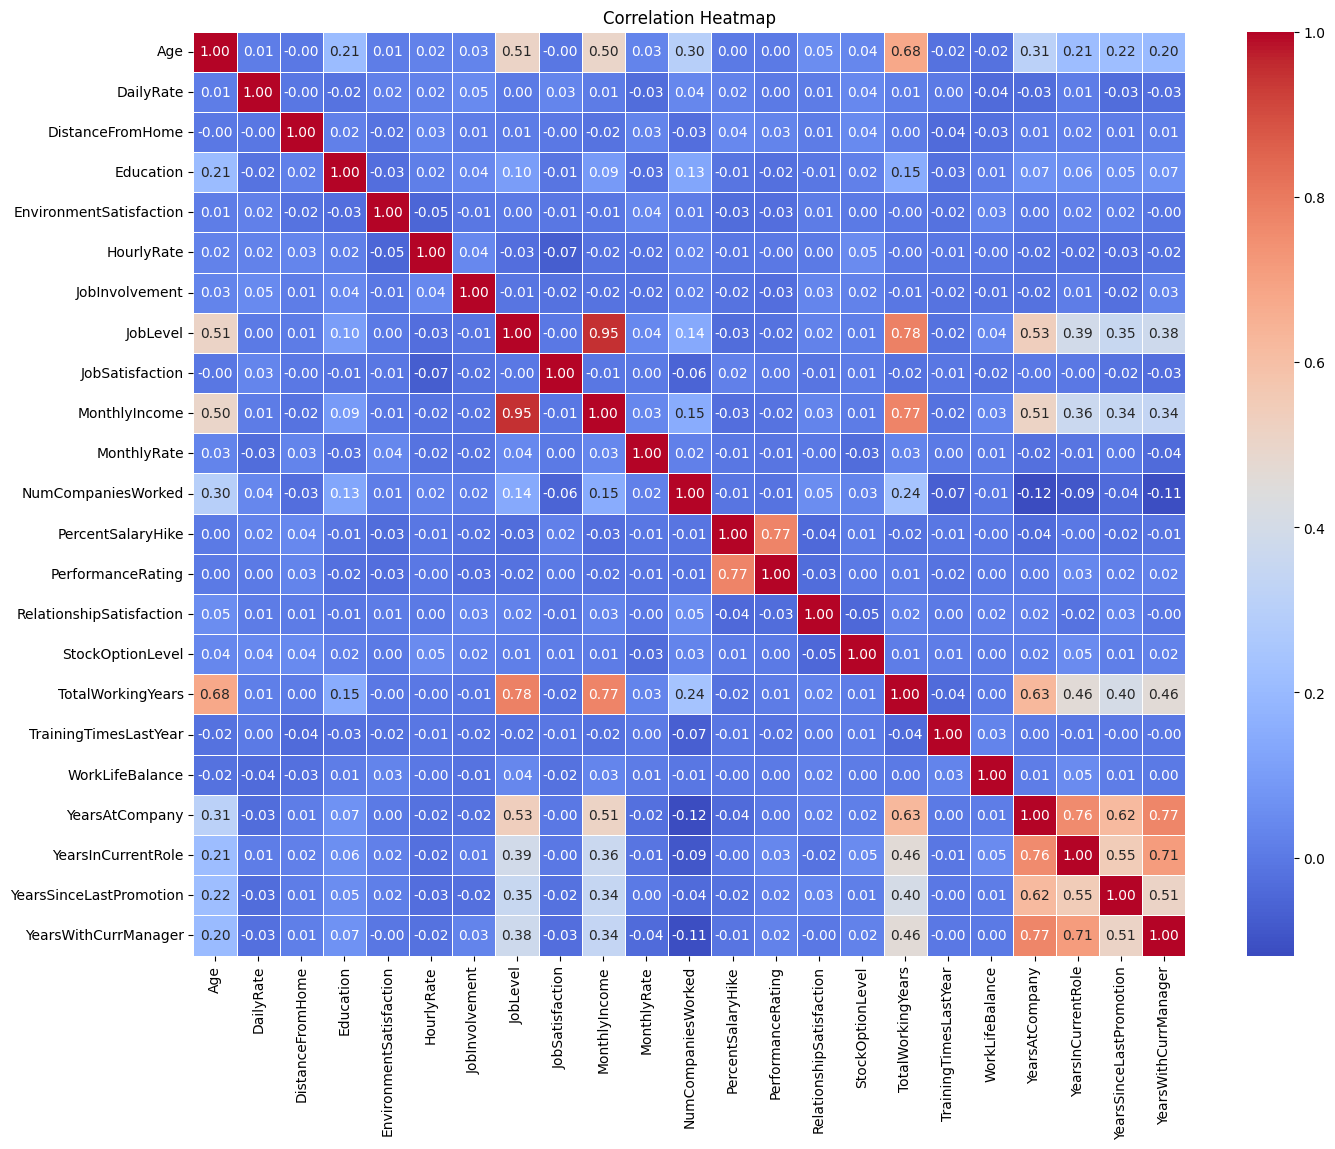

In [85]:
# Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(16,12))

sns.heatmap(
    df_clean.select_dtypes(include="number").corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

,Attrition
Attrition,1.000000
DistanceFromHome,0.077924
NumCompaniesWorked,0.043494
MonthlyRate,0.015170
PerformanceRating,0.002889
HourlyRate,-0.006846
PercentSalaryHike,-0.013478
Education,-0.031373
YearsSinceLastPromotion,-0.033019
RelationshipSatisfaction,-0.045872


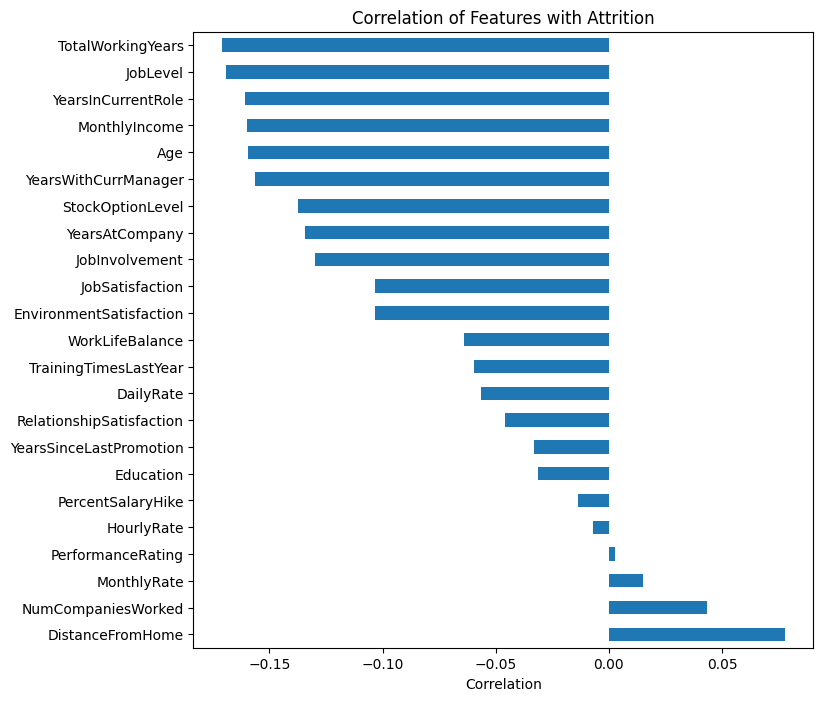

In [86]:
# Correlation with Attrition

df_corr = df_clean.copy()

df_corr["Attrition"] = df_corr["Attrition"].map({"Yes":1,"No":0})

corr = (
    df_corr.corr(numeric_only=True)["Attrition"]
    .sort_values(ascending=False)
)

display(corr)

plt.figure(figsize=(8,8))

corr.drop("Attrition").plot(kind="barh")

plt.title("Correlation of Features with Attrition")

plt.xlabel("Correlation")

plt.show()

In [87]:
df_clean.to_csv("clean_hr_data.csv", index=False)

In [88]:
import os

print(os.getcwd())

/content


In [89]:
print(df_clean.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'AgeGroup', 'IncomeGroup', 'ExperienceLevel', 'EducationLevel', 'EnvironmentLevel', 'WorkLifeLevel', 'RelationshipLevel']


In [90]:
# Numeric Attrition column for analysis
df_clean["AttritionNumeric"] = df_clean["Attrition"].map({
    "Yes": 1,
    "No": 0
})

In [91]:
df_clean[["Attrition", "AttritionNumeric"]].head()

,Attrition,AttritionNumeric
0,Yes,1
1,No,0
2,Yes,1
3,No,0
4,No,0


In [92]:
df_clean.to_csv(
    "HR_Analytics_Cleaned_Data.csv",
    index=False
)

print("Saved Successfully!")

Saved Successfully!


In [93]:
from google.colab import files

files.download("HR_Analytics_Cleaned_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>